# Seasonal variation

This notebook will be used to analyze and visualize the seasonal variation of the different water quality parameters from the water quality dataset.

In [2]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.interpolate import griddata
from pathlib import Path
import sys

# Ensure we use centralized paths (as per pipeline_summary.md)
# Ensure local scripts are importable
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
    
from scripts.paths import ProjectPaths

In [3]:
# --- Configuration & Parameters ---
season = 'Summer'
layer = 'bottom'
target_year = '1991' 
interpolation_method = 'linear' # Dynamic interpolation method to test

In [4]:
# --- Data Loading ---
# 1. Fetch subset pipeline directory 
subset_dir = ProjectPaths.get_subset_dir(season, layer)

# Use the raw yearly DO file before any pipeline spatial interpolation was applied
yearly_do_file = subset_dir / "yearly_do_df.csv"

if not yearly_do_file.exists():
    raise FileNotFoundError(f"Yearly DO data file not found: {yearly_do_file}")

# 2. Load the raw DO dataset. CRITICAL dtype FIX for zettaicode leading zero retention!
yearly_do_df = pd.read_csv(yearly_do_file, dtype={'zettaicode': str})
yearly_do_df.set_index('zettaicode', inplace=True)

# Handle dynamic column datatypes
if target_year not in yearly_do_df.columns and int(target_year) in yearly_do_df.columns:
    target_year = int(target_year)

# Drop missing values (NaNs) to ensure we ONLY interpolate from actual measurements
do_values = yearly_do_df[[target_year]].dropna().rename(columns={target_year: 'do_'})

# 3. Load spatial coordinates from merged geospatial data
merged_gdf = gpd.read_feather(ProjectPaths.MERGED_DATA_FILE)
stations_gdf = merged_gdf[['zettaicode', 'longitude', 'latitude']].drop_duplicates().set_index('zettaicode')

# Combine valid DO measurements with their precise spatial coordinates
plot_df = do_values.join(stations_gdf, how='inner')

if len(plot_df) < 4:
    raise ValueError(f"Insufficient actual measurement points for interpolation in {target_year}.")

In [5]:
# --- Interpolation ---
# Prepare the observed dataset geometries 
points = plot_df[['longitude', 'latitude']].values
values = plot_df['do_'].values

# Define geographical grid limits bounding the Seto Inland Sea
extent = [130.6, 135.6, 32.75, 35.1]
grid_x, grid_y = np.mgrid[extent[0]:extent[1]:200j, extent[2]:extent[3]:200j]

# Generate spatial interpolation across the Cartesian matrix grid
# Using 'linear' on the sparse scatter of `yearly_do_df` will triangulate between 
# the observed points and compute the surfaces.
grid_z = griddata(points, values, (grid_x, grid_y), method=interpolation_method)

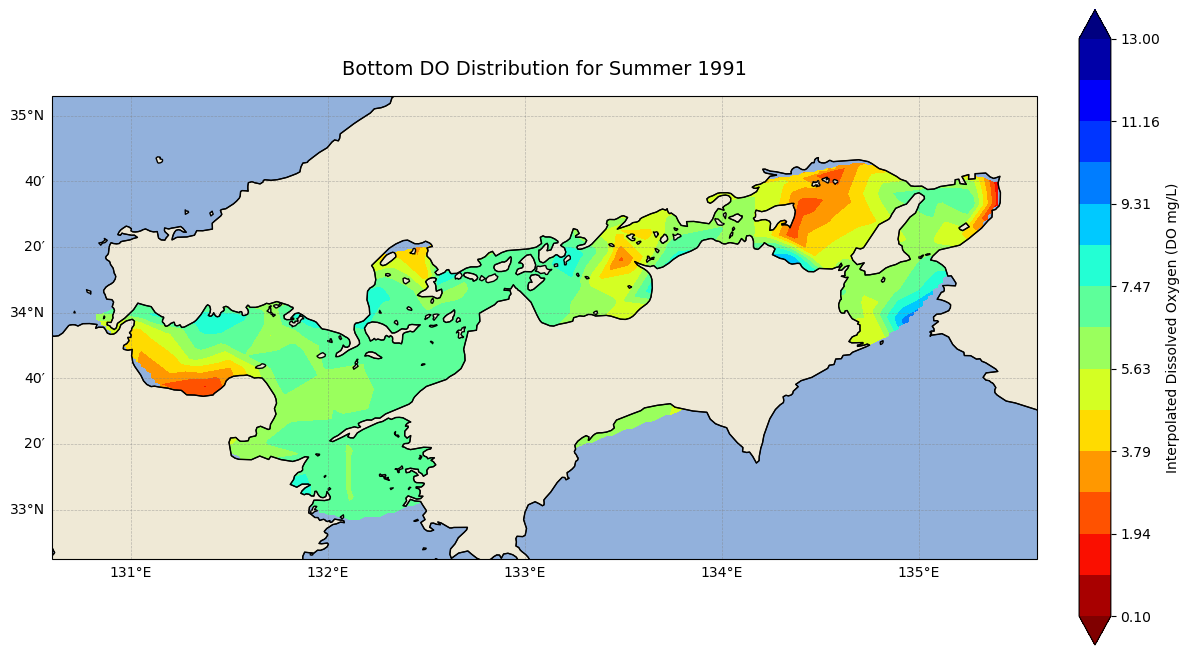

In [6]:
# --- Plotting & Visualization ---
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent(extent, crs=ccrs.PlateCarree())

# Set custom land and ocean color schemas matching your example output
land_feature = cfeature.NaturalEarthFeature(
    'physical', 'land', '10m', edgecolor='black', facecolor='#efe9d6'
)

# Visual stacking hierarchy (zorder) relies on Cartesian masking:
# Ocean [Z=0] -> Interpolated Sea Surface Contours [Z=1] -> Land masses masking out terrain [Z=2]
ax.add_feature(cfeature.OCEAN, zorder=0, facecolor='#92b1dc')

# Create discrete map levels from 0.1 to 13.00
vmin, vmax = 0.10, 13.00

contour = ax.contourf(
    grid_x, grid_y, grid_z,
    levels=np.linspace(vmin, vmax, 15), # 15 boundaries exactly create 14 color stepped buckets
    cmap='jet_r',                       # Reversed jet naturally maps 13 to dark blue and 0.1 to dark red
    transform=ccrs.PlateCarree(),
    zorder=1,
    extend='both'
)

# Apply Map masks OVER the terrain data
ax.add_feature(land_feature, zorder=2)
ax.add_feature(cfeature.COASTLINE, zorder=3, linewidth=0.8)

# Attach clean Cartesian Lat/Lon grids
gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, 
                  linewidth=0.5, color='gray', alpha=0.5, linestyle='--', zorder=4)
gl.top_labels = False
gl.right_labels = False

# Decorate explicit map aesthetics
cbar = fig.colorbar(contour, ax=ax, fraction=0.03, pad=0.04)
cbar.set_label('Interpolated Dissolved Oxygen (DO mg/L)')

# Force exact ticks on the colorbar matching your example figure metrics
cbar.set_ticks(np.linspace(vmin, vmax, 8))

ax.set_title(f'{layer.capitalize()} DO Distribution for {season} {target_year}', fontsize=14, pad=15)

plt.tight_layout()
plt.show()


/tmp/ipykernel_1474/2971897292.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Season', y='do_', data=combined_df, order=seasons, palette=colors, width=0.5)


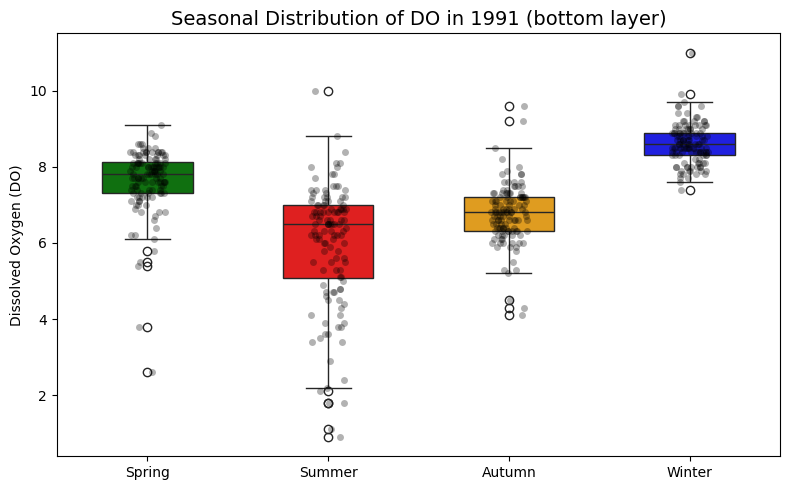

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Define seasons to compare
seasons = ['Spring', 'Summer', 'Autumn', 'Winter']
all_seasons_data = []

# Fetch data across all seasons for the currently defined layer and target_year
for s in seasons:
    subset_dir = ProjectPaths.get_subset_dir(s, layer)
    yearly_do_file = subset_dir / "yearly_do_df.csv"
    
    if yearly_do_file.exists():
        yearly_do_df = pd.read_csv(yearly_do_file, dtype={'zettaicode': str})
        yearly_do_df.set_index('zettaicode', inplace=True)
        
        # Verify the target_year matches the available column type (str or int)
        col_year = str(target_year) if str(target_year) in yearly_do_df.columns else int(target_year)
        
        if col_year in yearly_do_df.columns:
            # Extract only the target year's DO values and label the season
            do_values = yearly_do_df[[col_year]].dropna().rename(columns={col_year: 'do_'})
            do_values['Season'] = s
            all_seasons_data.append(do_values)

# If data successfully loaded, concatenate and plot
if all_seasons_data:
    combined_df = pd.concat(all_seasons_data)
    
    # Configure the Box/Strip-Plot
    plt.figure(figsize=(8, 5))
    colors = {'Spring': 'green', 'Summer': 'red', 'Autumn': 'orange', 'Winter': 'blue'}
    
    sns.boxplot(x='Season', y='do_', data=combined_df, order=seasons, palette=colors, width=0.5)
    sns.stripplot(x='Season', y='do_', data=combined_df, order=seasons, color='black', alpha=0.3, jitter=True)
    
    plt.title(f'Seasonal Distribution of DO in {target_year} ({layer} layer)', fontsize=14)
    plt.ylabel('Dissolved Oxygen (DO)')
    plt.xlabel('')
    
    plt.tight_layout()
    plt.show()
else:
    print(f"No seasonal data found for the year {target_year}.")


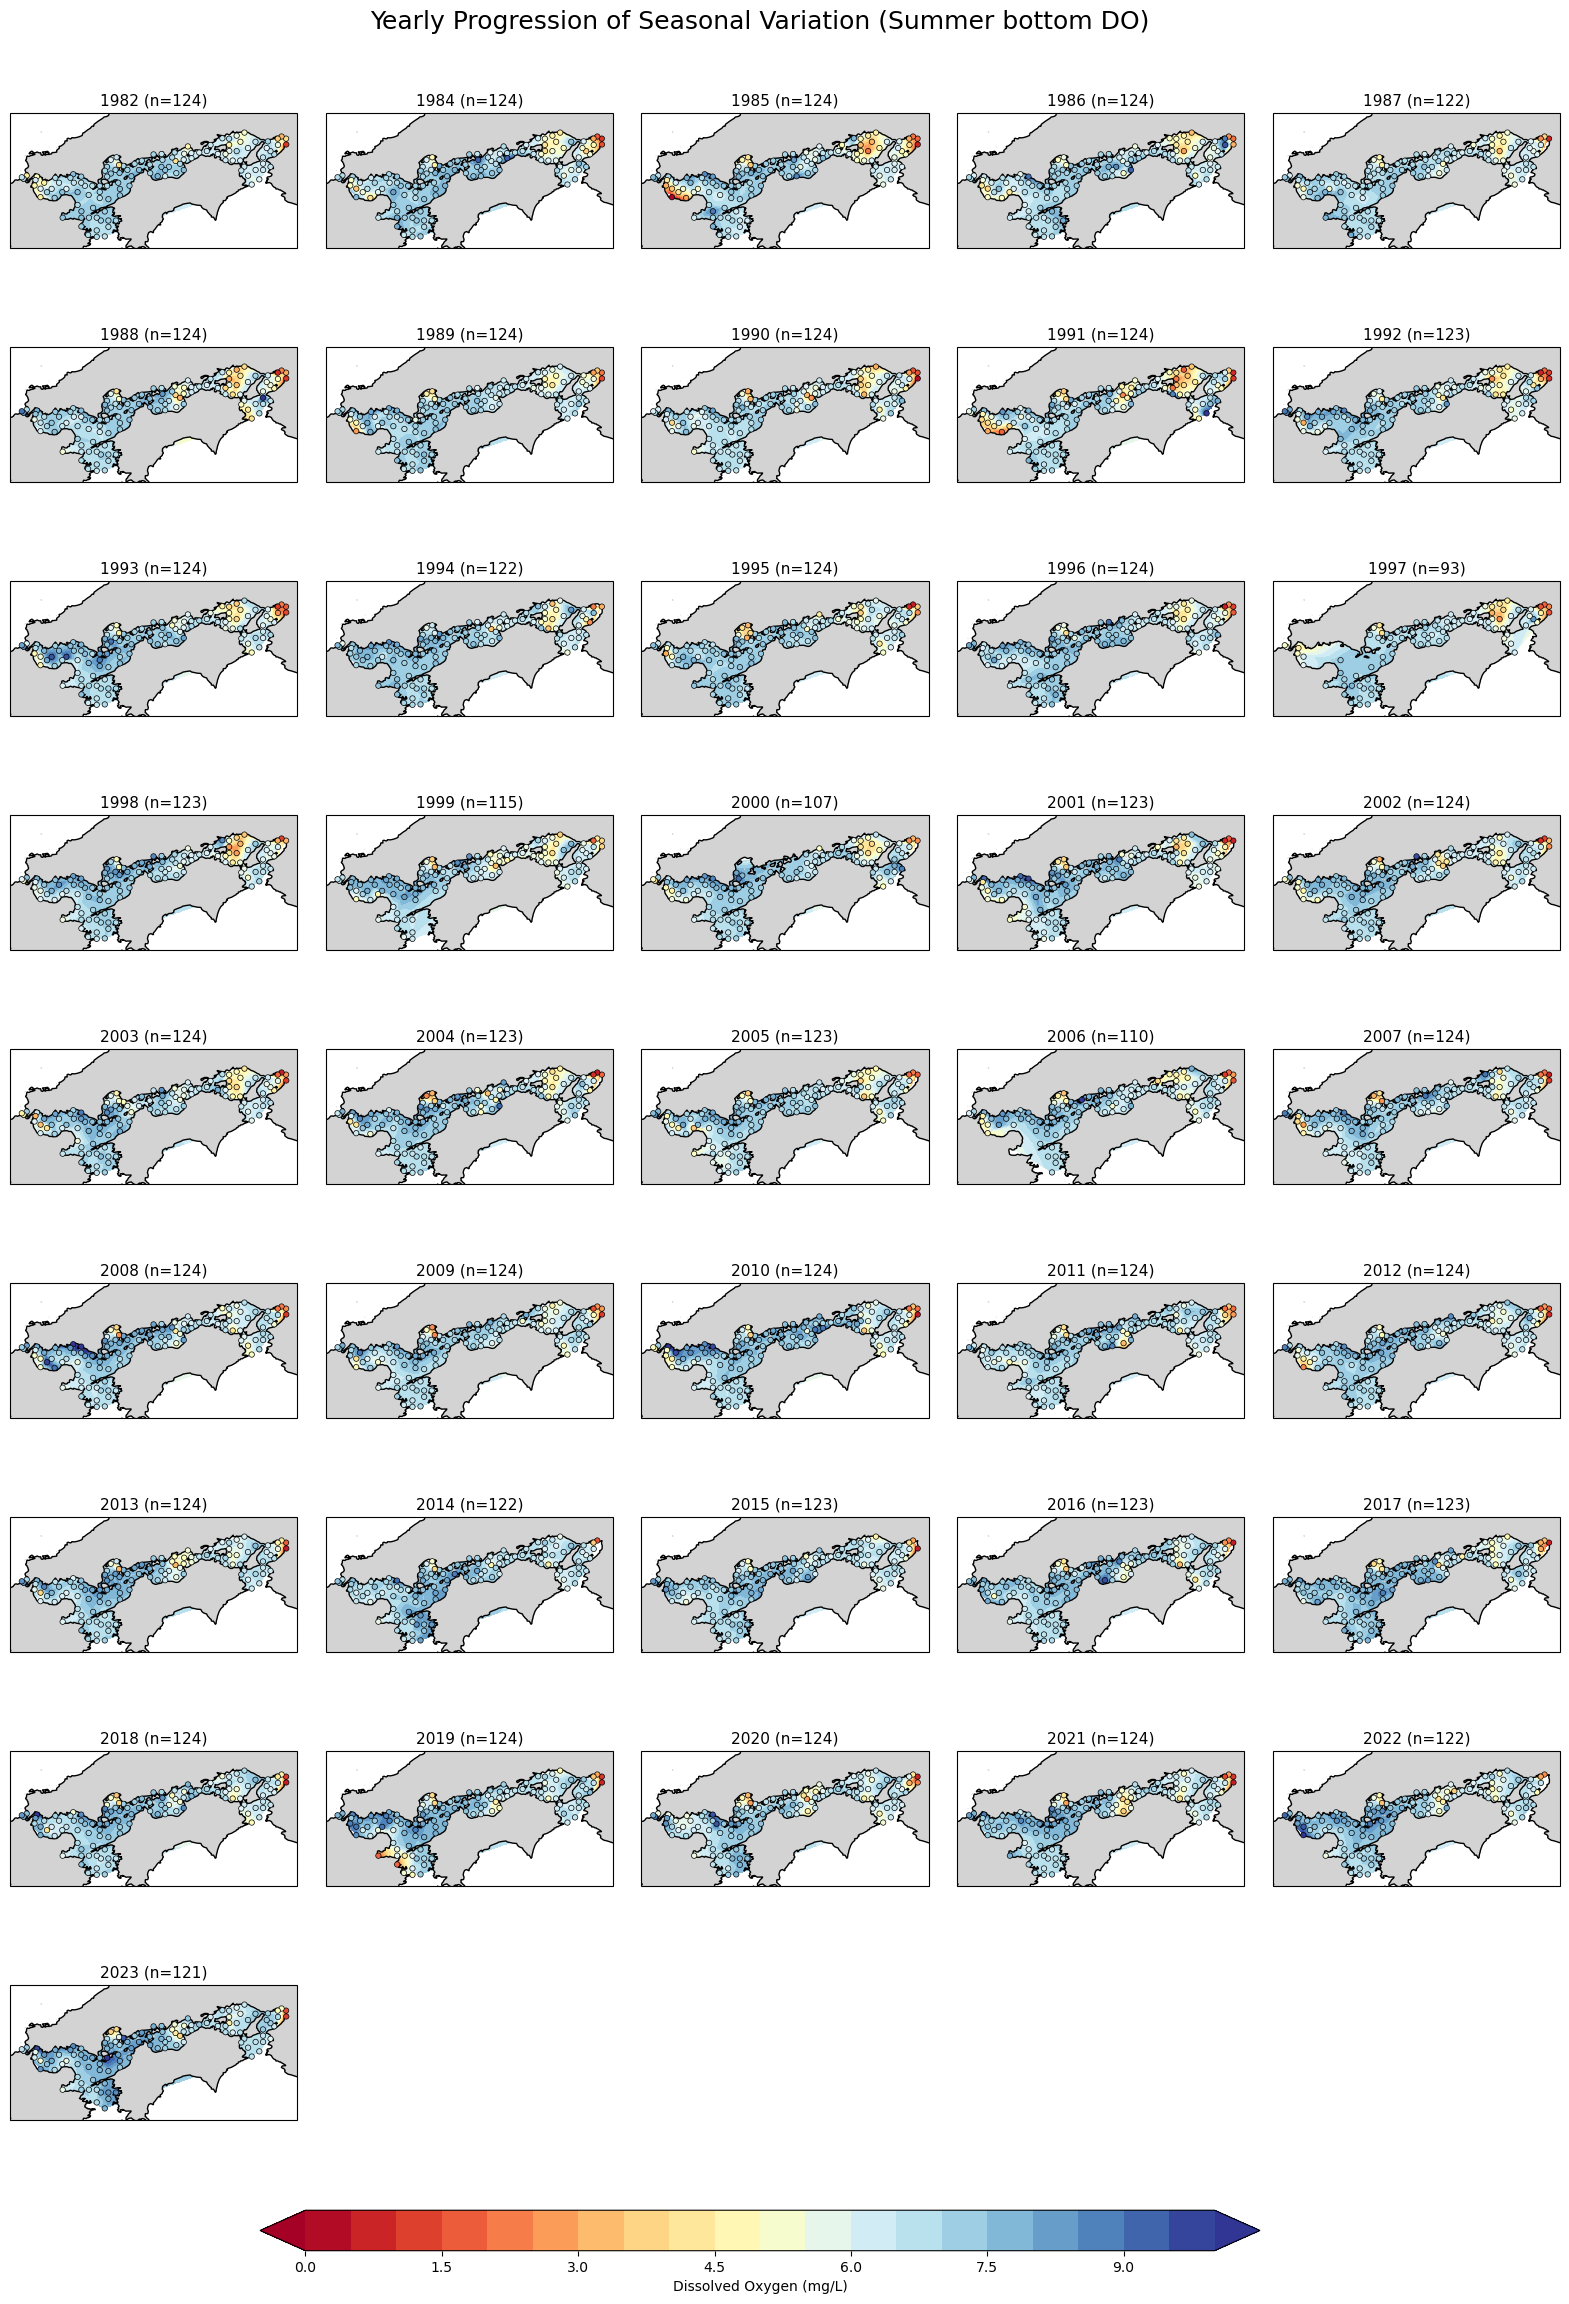

In [8]:
import math
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from scipy.interpolate import griddata

# 1. Fetch available years, explicitly excluding metadata columns, and sort them chronologically
available_years = [col for col in yearly_do_df.columns if col != 'zettaicode']
available_years = sorted(available_years, key=int)

# 2. Configure Subplot Grid for 5 columns and dynamic rows
cols = 5
rows = math.ceil(len(available_years) / cols)

# Define Cartopy projection
proj = ccrs.PlateCarree()

# Create figure (Scaling height accordingly to adapt to the 9 rows needed)
fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3), 
                         subplot_kw={'projection': proj})

# Flatten axes for easy iteration
axes = axes.flatten()

# 3. Use the exact boundaries and 200j grid step size from the single plot
extent = [130.6, 135.6, 32.75, 35.1]
grid_x, grid_y = np.mgrid[extent[0]:extent[1]:200j, extent[2]:extent[3]:200j]

# 4. Enforce identical static levels and colors mapped exactly to the single plot
levels = np.linspace(0, 10, 21)
cmap = 'RdYlBu'

contour = None

for i, ax in enumerate(axes):
    if i < len(available_years):
        year = available_years[i]
        
        # Extract data for the specific year
        do_values = yearly_do_df[[str(year)]].dropna().rename(columns={str(year): 'do_'})
        plot_df = do_values.join(stations_gdf, how='inner')
        
        # Set geographical viewport
        ax.set_extent(extent, crs=proj)
        
        if len(plot_df) >= 4:
            points = plot_df[['longitude', 'latitude']].values
            values = plot_df['do_'].values
            
            # Generate spatial interpolation
            grid_z = griddata(points, values, (grid_x, grid_y), method=interpolation_method)
            
            # Filled contours constrained explicitly by `levels` (zorder=1)
            contour = ax.contourf(grid_x, grid_y, grid_z, levels=levels, cmap=cmap, 
                                  extend='both', transform=proj, zorder=1)
            
            # Plot actual measurement points on top (zorder=3)
            ax.scatter(points[:, 0], points[:, 1], c=values, cmap=cmap, s=15, 
                       edgecolor='black', linewidth=0.5, zorder=3, transform=proj, 
                       vmin=0, vmax=10)
            
        # Add land mask ON TOP of the interpolation but UNDER the scatters (zorder=2)
        ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=2)
        ax.add_feature(cfeature.COASTLINE, zorder=2)
        
        # Dynamically label title with subset size observation
        ax.set_title(f"{year} (n={len(plot_df)})", fontsize=11)
        
    else:
        # Hide any unused subplots
        ax.set_visible(False)

# Add a single shared colorbar placed properly across all subplots
if contour is not None:
    cbar_ax = fig.add_axes([0.25, 0.08, 0.5, 0.015]) # [left, bottom, width, height]
    fig.colorbar(contour, cax=cbar_ax, orientation='horizontal', label="Dissolved Oxygen (mg/L)", extend='both')

# Adjust layout slightly to account for the overall 5x9 grid height
plt.subplots_adjust(bottom=0.12, hspace=0.3, wspace=0.1)
plt.suptitle(f"Yearly Progression of Seasonal Variation ({season} {layer} DO)", fontsize=18, y=0.91)
plt.show()


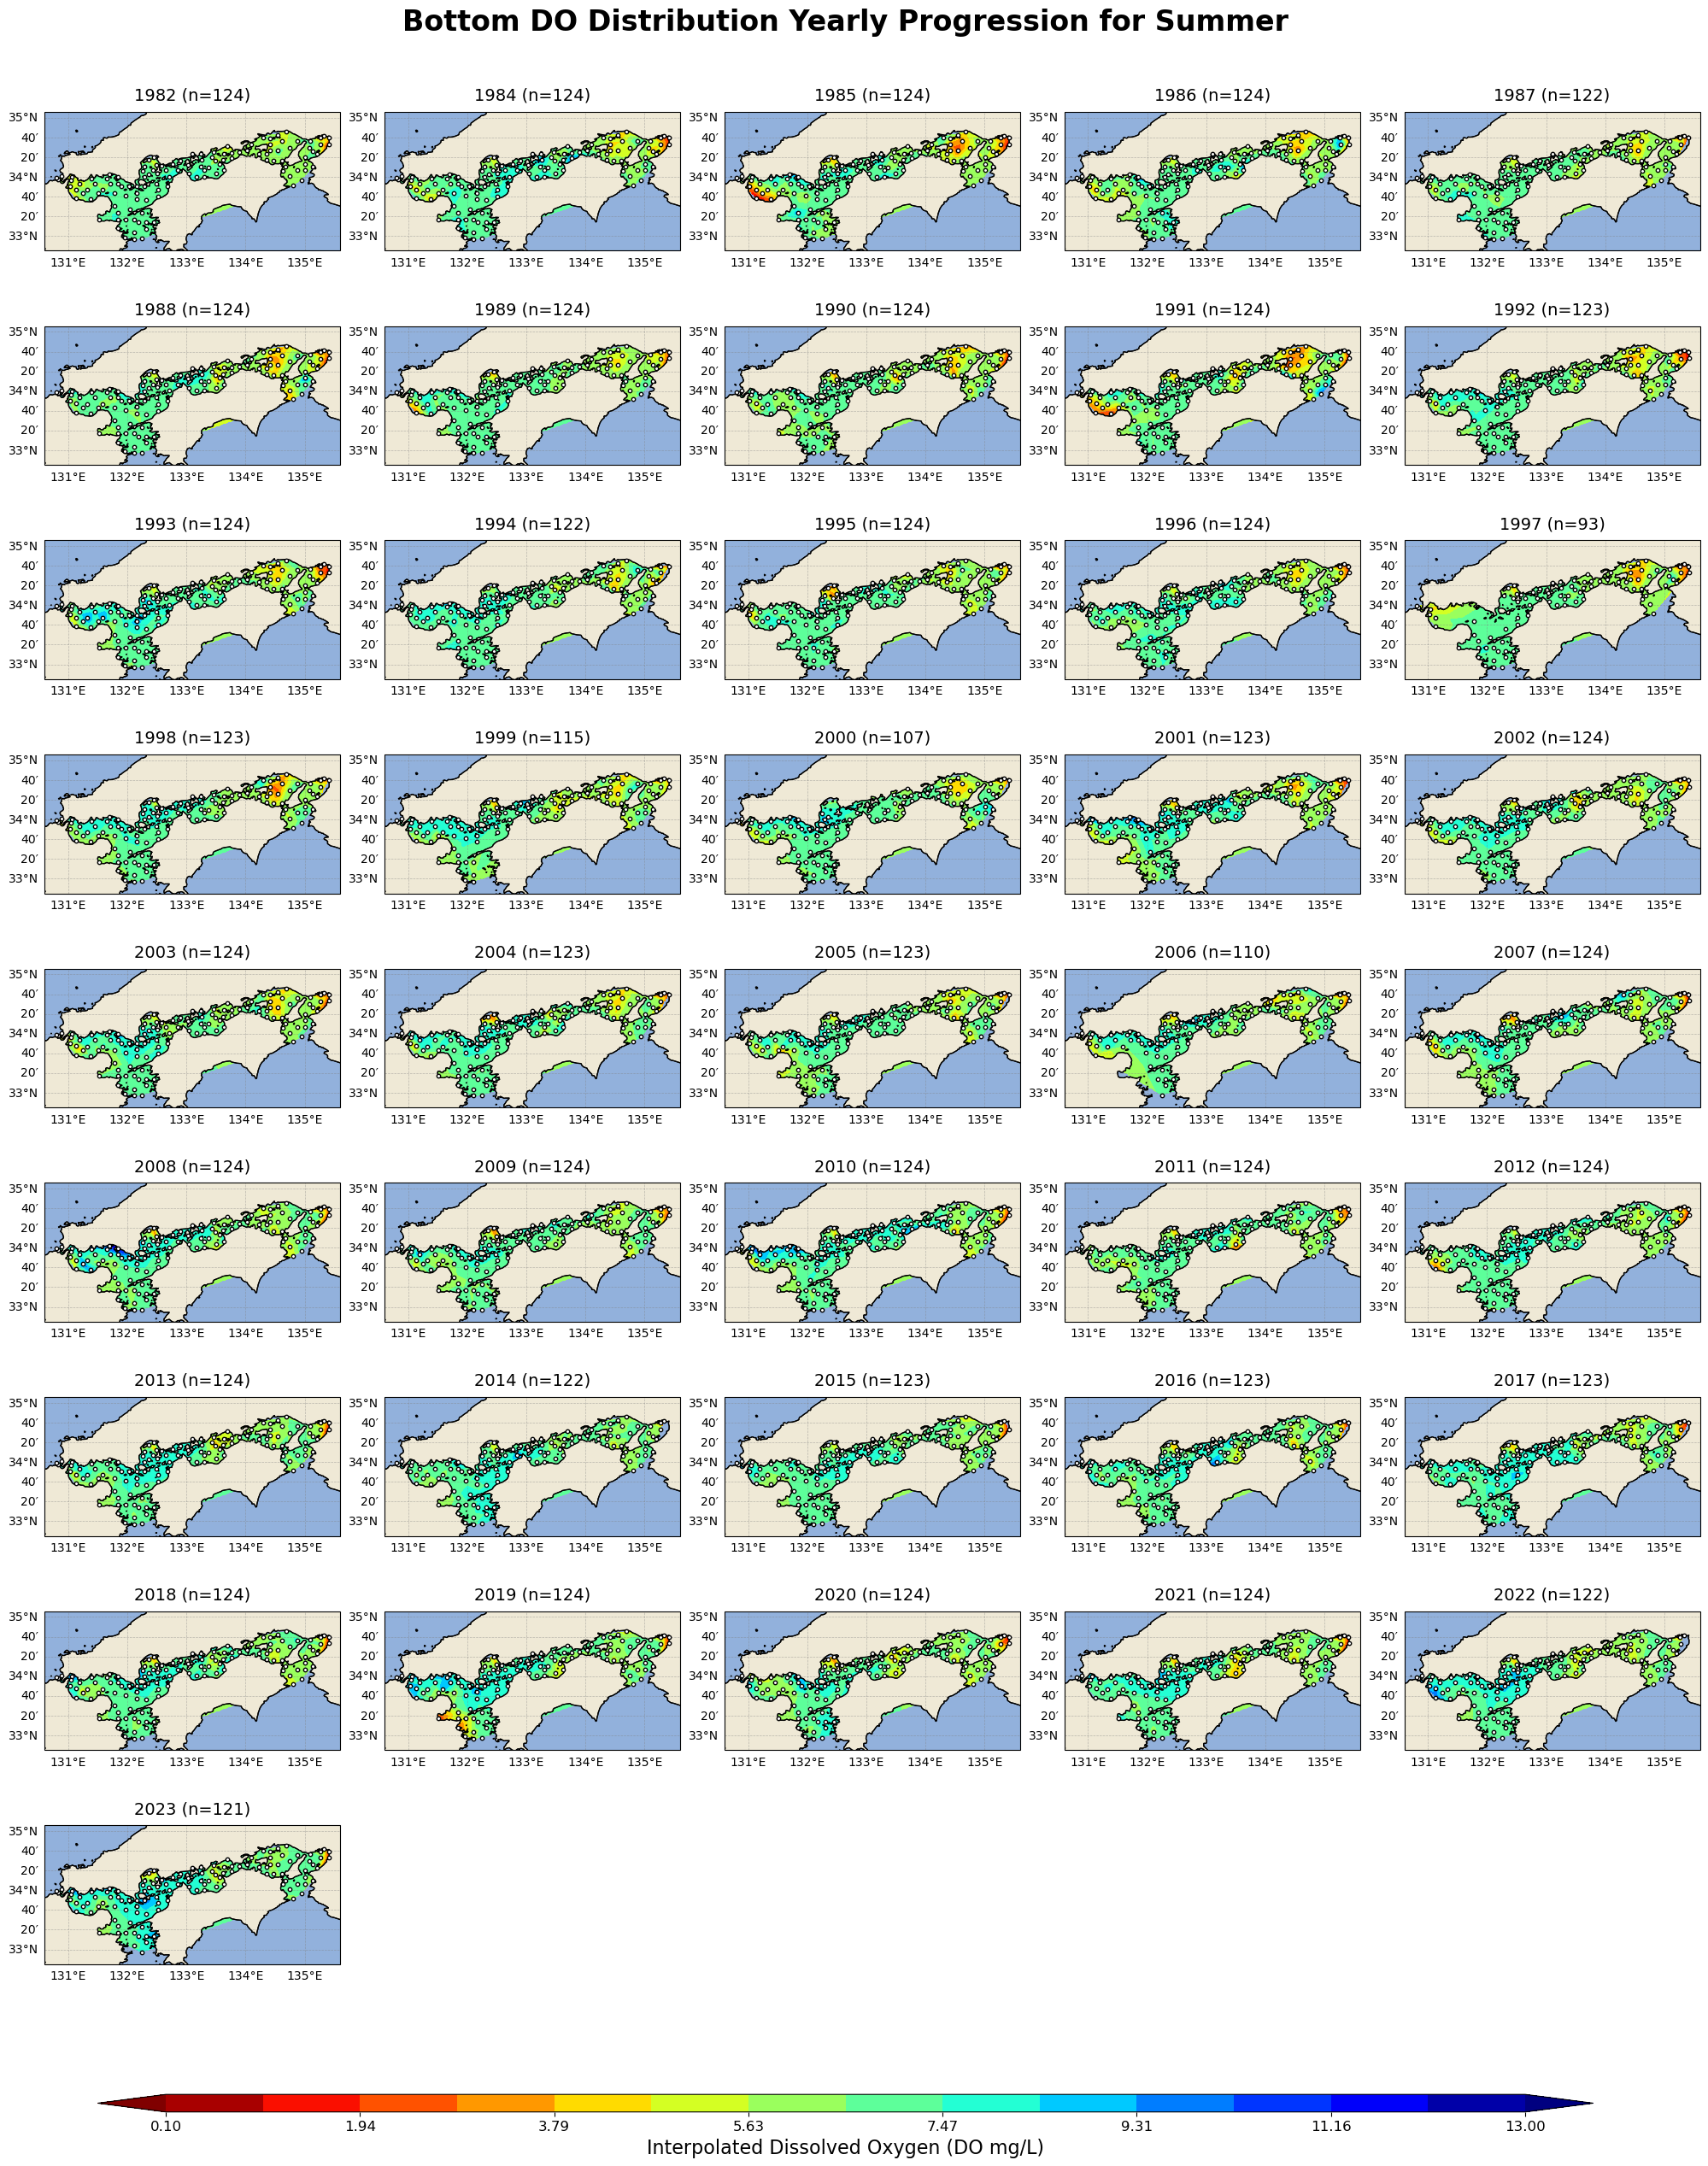

In [11]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.interpolate import griddata
from pathlib import Path
import sys

# Ensure we use centralized paths
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
    
from scripts.paths import ProjectPaths

# --- Configuration & Parameters ---
season = 'Summer'
layer = 'bottom'
interpolation_method = 'linear'

# --- Data Loading ---
subset_dir = ProjectPaths.get_subset_dir(season, layer)
yearly_do_file = subset_dir / "yearly_do_df.csv"

if not yearly_do_file.exists():
    raise FileNotFoundError(f"Yearly DO data file not found: {yearly_do_file}")

# Load the raw DO dataset.
yearly_do_df = pd.read_csv(yearly_do_file, dtype={'zettaicode': str})
yearly_do_df.set_index('zettaicode', inplace=True)

# Load spatial coordinates
merged_gdf = gpd.read_feather(ProjectPaths.MERGED_DATA_FILE)
stations_gdf = merged_gdf[['zettaicode', 'longitude', 'latitude']].drop_duplicates().set_index('zettaicode')

# --- Determine Subplots Layout ---
available_years = [col for col in yearly_do_df.columns if str(col).isdigit()]
available_years = sorted(available_years, key=lambda x: int(x))
n_years = len(available_years)

# Determine Map Boundaries and Optimal Subplot Aspect Ratios
extent = [130.6, 135.6, 32.75, 35.1]
aspect_ratio = (extent[3] - extent[2]) / (extent[1] - extent[0]) 

n_cols = 5
n_rows = int(np.ceil(n_years / n_cols))

fig_width = 25
width_per_subplot = fig_width / n_cols
# Apply exact map bounds mapping + slight text bumper 
height_per_subplot = (width_per_subplot * aspect_ratio) + 0.5 
fig_height = height_per_subplot * n_rows 

# Create grid of subplots vertically down avoiding padding gaps
fig, axes = plt.subplots(n_rows, n_cols, figsize=(fig_width, fig_height), subplot_kw={'projection': ccrs.PlateCarree()})
axes = axes.flatten()

grid_x, grid_y = np.mgrid[extent[0]:extent[1]:200j, extent[2]:extent[3]:200j]

land_feature = cfeature.NaturalEarthFeature(
    'physical', 'land', '10m', edgecolor='black', facecolor='#efe9d6'
)

# Discrete map levels from 0.1 to 13.00 with exactly 15 boundaries
vmin, vmax = 0.10, 13.00
levels = np.linspace(vmin, vmax, 15)

# --- Subplot Generation ---
for i, year in enumerate(available_years):
    ax = axes[i]
    
    do_values = yearly_do_df[[year]].dropna().rename(columns={year: 'do_'})
    plot_df = do_values.join(stations_gdf, how='inner')
    
    if len(plot_df) < 4:
        ax.set_visible(False)
        continue
        
    points = plot_df[['longitude', 'latitude']].values
    values = plot_df['do_'].values
    
    # Spatial interpolation using griddata
    grid_z = griddata(points, values, (grid_x, grid_y), method=interpolation_method)
    
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.OCEAN, zorder=0, facecolor='#92b1dc')
    
    # Layer 1: Interpolated Sea Surface Contours
    contour = ax.contourf(
        grid_x, grid_y, grid_z,
        levels=levels,
        cmap='jet_r',
        transform=ccrs.PlateCarree(),
        zorder=1,
        extend='both'
    )
    
    ax.add_feature(land_feature, zorder=2)
    ax.add_feature(cfeature.COASTLINE, zorder=3, linewidth=0.8)
    
    # Clean Cartesian Lat/Lon grids
    gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, 
                      linewidth=0.5, color='gray', alpha=0.5, linestyle='--', zorder=4)
    gl.top_labels = False
    gl.right_labels = False
    
    # Extracted data points
    ax.scatter(plot_df['longitude'], plot_df['latitude'], c='white', edgecolors='black', s=10, zorder=5, transform=ccrs.PlateCarree())
    
    # Subplot Title padding
    ax.set_title(f"{year} (n={len(plot_df)})", fontsize=14, pad=10)

# Hide completely unused layout boxes
for j in range(len(available_years), len(axes)):
    axes[j].set_visible(False)

# --- Global Styling & Shared Elements ---
# Tweak inner subplot spacing to complement new dimensions
plt.subplots_adjust(bottom=0.08, top=0.94, hspace=0.25, wspace=0.15)

# Coordinate layout axes bounds parameters explicitly [left, bottom, width, height]
cbar_ax = fig.add_axes([0.15, 0.02, 0.7, 0.008])  
cbar = fig.colorbar(contour, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Interpolated Dissolved Oxygen (DO mg/L)', fontsize=16)
cbar.set_ticks(np.linspace(vmin, vmax, 8))
cbar.ax.tick_params(labelsize=12)

# Figure Title
plt.suptitle(f'{layer.capitalize()} DO Distribution Yearly Progression for {season}', fontsize=24, y=0.98, fontweight='bold')

plt.show()
